# Angular clustering with a Rubin magnitude-limited sample

Rubin's cosmology program rests on two main probes of how matter clusters: weak lensing, and
the clustering of galaxies themselves. This notebook is about the second one. We'll use a
~113 deg² patch of real Rubin DP2 imaging, centered on the same coordinates as Week 7, to
build a galaxy sample, work out where the data are actually good enough to trust, correct for
the usual ways a telescope and the atmosphere can fake a clustering signal, and then measure
that clustering in its two standard forms: the angular correlation function w(θ), and its
harmonic-space counterpart, the angular power spectrum C(ℓ).

DP2 is still commissioning and science-validation data, well short of the depth and area the
finished survey will reach, so there's no Rubin paper yet that runs this analysis at full
scale. We borrow the design instead from the Dark Energy Survey, which just finished doing
almost exactly this: the MagLim lens-sample definition from Porredon et al. (2021,
[arXiv:2011.03411](https://arxiv.org/abs/2011.03411)), and the systematics treatment from
Rodríguez-Monroy et al. (2022, [arXiv:2105.13540](https://arxiv.org/abs/2105.13540)). The
quantity you end up with — a clustering amplitude, and what it implies about galaxy bias —
is the same kind of measurement that feeds DES's headline cosmological result (Abbott et al.
2022, [arXiv:2105.13549](https://arxiv.org/abs/2105.13549)). Next class fills in the piece
that's missing here: a model for how matter itself clusters, which turns today's relative
bias measurements into absolute ones.

The notebook works through this in order: select the sample, mask and correct it, then
measure clustering twice over, once as w(θ) and once as C(ℓ). Each section ends with a short
conceptual Questions box and, in most cases, a hands-on Exercise; a final section, Going
deeper, collects three more involved exercises for afterward.

**AI-use note.** This notebook was developed with the help of an AI assistant, Claude Sonnet 5
(Anthropic; model ID `claude-sonnet-5`), used through Claude Code.

**Science objective:** build a DES-style MagLim lens galaxy sample from Rubin DP2, mask and
systematics-correct it the way a real cosmology analysis would, and measure its angular
clustering — the angular correlation function w(θ) in tomographic redshift bins with
TreeCorr, and the angular power spectrum C(ℓ) with NaMaster (proper mode-coupling
deconvolution and template deprojection) — to see how galaxy selection, photometric
redshifts, and observational systematics interact in a real imaging survey.

**Learning objective:** how a magnitude-limited photometric galaxy sample is built and
masked; how observational systematics (depth, seeing, sky noise, stellar density, dust)
imprint spurious clustering, and how to diagnose and remove it; how angular clustering
connects to galaxy bias; how the same signal looks in configuration space (w(θ)) versus
harmonic space (C(ℓ)).

**Data products:** `dp2.Object` (TAP), `object_photoz` (LSDB/HATS), DP2 survey property maps
(Butler).


## 1. Setup

Imports, region and selection parameters, a TAP connection, and (optionally) a precomputed-data shortcut — everything the rest of the notebook depends on.


In [1]:
import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import healpy as hp
import hpgeom as hpg
import healsparse
import treecorr
import lsdb
from upath import UPath
from lsst.daf.butler import Butler
from lsst.rsp import RSPDiscovery


### 1.1. Region and selection parameters

`RADIUS_DEG` sets a circular query region of area `pi * RADIUS_DEG**2`. Three presets are
noted in the cell below (1, 3, 6 deg radius); the full-footprint default is ~113 deg², in the
middle of the requested 100-300 deg² range, chosen to keep the TAP query and the pandas/LSDB
join comfortably within class time. Ambitious students can grow `RADIUS_DEG` toward the full
footprint — see the note in Section 1.3 about the join's ~1M row guideline.

`FAINT_PRECUT` is a loose faint-end cut applied at the TAP stage only, to bound the amount of
data pulled before the photo-z join. It is well below the typical depth where the exact
MagLim relation would cut anyway (`i = 4*z_phot + 18` reaches 23 mag only for `z_phot > 1.25`),
so it should not bias the final sample for a low-to-moderate redshift lens selection. The
true MagLim-style cut is re-applied exactly, using the joined photo-z, in Section 2.

Every Butler survey-property map fetched in Section 3 is cached to disk under `MAP_CACHE_DIR`
(see Section 3.2), so repeated runs with the same parameters skip the slow Butler I/O entirely
after the first.


In [2]:
RA_CENTER = 345.0
DEC_CENTER = -8.2
# Region size presets (radius in degrees, area in deg^2):
#   1.0 deg ~  3 deg^2   - fast end-to-end sanity check
#   3.0 deg ~ 28 deg^2   - medium: confirms the LSDB join scales past ~1M rows
#   6.0 deg ~113 deg^2   - full footprint
RADIUS_DEG = 6.0

BAND = 'i'
MAG_BRIGHT = 17.5
FAINT_PRECUT = 23.0
MAGLIM_SLOPE = 4.0
MAGLIM_INTERCEPT = 18.0

N_ZBINS = 4
Z_EDGES = np.linspace(0.0, 1.0, N_ZBINS + 1)

MASK_NSIDE = 4096
DIAG_NSIDE = 512
DEPTH_MARGIN_MAG = 1.0
STAR_MAG_BRIGHT = 17.5
STAR_MAG_FAINT = 21.0
STELLAR_DENSITY_PERCENTILE = 90.0

# Cached inputs (query results and survey-property maps) are read from the local data/ dir
# first, then from SHARED_DATA_DIR, a read-only copy of the full-footprint cache built by
# prepare_data.py, so you can skip the slow TAP/LSDB/Butler steps. Anything newly computed
# is always written locally, never to the shared dir.
SHARED_DATA_DIR = '/home/kstoreyf/phys367/week8/data'
MAP_CACHE_DIR = os.path.join('data', 'maps')

RAND_FACTOR = 15
MAX_RANDOMS = 2_000_000

TC_MIN_SEP_ARCMIN = 1.0
# Keep max_sep well under the patch radius: near half the radius, galaxy/random pairs close
# to the footprint boundary are incompletely sampled, which biases the largest-scale bins far
# beyond what their (shot-noise-only) error bars suggest. 0.2x is a safer margin than 0.5x.
TC_MAX_SEP_ARCMIN = min(250.0, RADIUS_DEG * 60.0 * 0.2)
TC_NBINS = 15

area_deg2 = np.pi * RADIUS_DEG**2
print('Query region: {:.2f} deg radius, {:.2f} deg^2'.format(RADIUS_DEG, area_deg2))


Query region: 6.00 deg radius, 113.10 deg^2


### 1.2. Connect to the TAP service

Get a TAP client for the `dp2` service, and a small helper that submits an ADQL query and waits for it to complete.


In [3]:
discovery = RSPDiscovery("dp2")
service = discovery.get_tap_client()
assert service is not None


def run_query(query):
    """Submit an ADQL query as an async TAP job and return an astropy table."""
    job = service.submit_job(query)
    job.run()
    job.wait(phases=['COMPLETED', 'ERROR'])
    print('Job phase is', job.phase)
    if job.phase == 'ERROR':
        job.raise_if_error()
    assert job.phase == 'COMPLETED'
    table = job.fetch_result().to_table()
    job.delete()
    return table


### 1.3. Load precomputed data if available

Section 2 (the TAP query, photo-z join, and MagLim cut) is the slow, failure-prone part of
this notebook at full scale — the full region pulls millions of objects, well past the
~1 million row guideline for the in-memory LSDB join. At the default settings it takes
**about 6 minutes**, mostly waiting on the TAP query rather than on CPU; expect it to run
once, not every time. `prepare_data.py` runs that part once
and saves the result to `data/`; if a cache is found there that matches the current
parameters (checked against `data/meta.json`), load it directly and skip straight to the
mask in Section 3. A mismatched or missing cache just falls back to running Section 2 live,
same as before. A live run also writes its own result to this same cache afterward, so it
stays usable either way.

In [4]:
USE_PRECOMPUTED_DATA = True
PRECOMPUTED_DATA_DIR = 'data'

current_params = {
    'ra_center': RA_CENTER, 'dec_center': DEC_CENTER, 'radius_deg': RADIUS_DEG,
    'band': BAND, 'mag_bright': MAG_BRIGHT, 'faint_precut': FAINT_PRECUT,
    'maglim_slope': MAGLIM_SLOPE, 'maglim_intercept': MAGLIM_INTERCEPT,
    'n_zbins': N_ZBINS, 'z_max': float(Z_EDGES[-1]),
}

data_loaded_from_cache = False
if USE_PRECOMPUTED_DATA:
    for data_dir in dict.fromkeys([PRECOMPUTED_DATA_DIR, SHARED_DATA_DIR]):
        meta_path = os.path.join(data_dir, 'meta.json')
        objects_path = os.path.join(data_dir, 'objects.parquet')
        galaxies_path = os.path.join(data_dir, 'galaxies.parquet')
        if not (os.path.exists(meta_path) and os.path.exists(objects_path)
                and os.path.exists(galaxies_path)):
            print('No precomputed data found in {!r}.'.format(data_dir))
            continue
        with open(meta_path) as f:
            cached_params = json.load(f)
        mismatched = {k: (cached_params.get(k), v) for k, v in current_params.items()
                      if cached_params.get(k) != v}
        if mismatched:
            print('Precomputed data in {!r} does not match current parameters, ignoring it:'
                  .format(data_dir))
            for k, (cached, now) in mismatched.items():
                print('  {}: cached={}, current={}'.format(k, cached, now))
            continue
        obj_df_renamed = pd.read_parquet(objects_path)
        galaxies = pd.read_parquet(galaxies_path)
        PZ_CODE = cached_params['pz_code']
        pz_col = cached_params['pz_col']
        data_loaded_from_cache = True
        print('Loaded precomputed data from {!r}: {} objects, {} galaxies'.format(
            data_dir, cached_params['n_objects'], cached_params['n_galaxies']))
        break
if not data_loaded_from_cache:
    print('Running the live pipeline; results will be saved to {!r}.'.format(PRECOMPUTED_DATA_DIR))


Loaded precomputed data from 'data': 3433204 objects, 180237 galaxies


<div class="alert alert-block alert-info">
<b>Exercise I: warm-up</b>

Tell your notebook partner (or someone sitting next to you) something you've appreciated about having
them in class :)
</div>


## 2. Galaxy selection

Clustering analyses need a tracer population that's defined once and reproducible exactly,
not just "galaxies" in some loose sense. The flag cuts below remove stars and bad photometry;
the MagLim cut and tomographic binning (Section 2.3) then turn that clean catalog into a
magnitude-limited lens sample split by redshift, so the final measurement can track how
clustering evolves with z rather than washing all of it into one number.

Select extended sources with clean i-band photometry flags, join photo-z, and apply a
MagLim-style cut, split into tomographic bins.

**The next two cells are the slow part of the notebook — about 6 minutes, mostly spent
waiting on the TAP query rather than on CPU. Run them and go grab a coffee; Section 1.3's
cache means you only pay this cost once.**


### 2.1. Query the Object catalog

Extended sources with clean i-band photometry flags, in the region, between the bright limit
and the faint pre-cut. The flag set follows the
[DP2 flag use examples](https://dp2.lsst.io/products/flags/flag_usage.html), with
`{band}_psfFlux_flag` swapped for `{band}_cModel_flag` since the selection is built on
CModel photometry (the recommended substitution for whichever flux type is actually used).

In [5]:
if not data_loaded_from_cache:
    columns = [
        'objectId', 'coord_ra', 'coord_dec', 'refExtendedness', 'ebv',
        '{0}_cModelMag'.format(BAND), '{0}_cModelMagErr'.format(BAND),
        '{0}_inputCount'.format(BAND), '{0}_cModel_flag'.format(BAND),
        '{0}_invalidPsfFlag'.format(BAND),
        '{0}_pixelFlags_saturatedCenter'.format(BAND),
        '{0}_pixelFlags_interpolatedCenter'.format(BAND),
    ]

    query = (
        "SELECT " + ", ".join(columns) + " "
        "FROM dp2.Object "
        "WHERE CONTAINS(POINT('ICRS', coord_ra, coord_dec), "
        "CIRCLE('ICRS', {ra}, {dec}, {radius})) = 1 "
        "AND refExtendedness = 1 "
        "AND {b}_inputCount > 0 "
        "AND {b}_cModel_flag = 0 "
        "AND {b}_invalidPsfFlag = 0 "
        "AND {b}_pixelFlags_saturatedCenter = 0 "
        "AND {b}_pixelFlags_interpolatedCenter = 0 "
        "AND {b}_cModelMag > {bright} "
        "AND {b}_cModelMag < {faint}"
    ).format(ra=RA_CENTER, dec=DEC_CENTER, radius=RADIUS_DEG, b=BAND,
             bright=MAG_BRIGHT, faint=FAINT_PRECUT)
    print(query)

    obj_table = run_query(query)
    obj_df = obj_table.to_pandas()
    print(len(obj_df), 'extended, clean-flag objects in the region')

    MAX_JOIN_ROWS = 1_000_000
    if len(obj_df) > MAX_JOIN_ROWS:
        print('Warning: {} rows exceeds the recommended size for an in-memory LSDB join '
              '({}). Reduce RADIUS_DEG or tighten FAINT_PRECUT before continuing.'
              .format(len(obj_df), MAX_JOIN_ROWS))


### 2.2. Join photo-z on `objectId`

DP2 photo-z estimates are distributed only as an LSDB/HATS catalog (`object_photoz`), not as
a TAP-joinable table. Convert the Object query result to an LSDB catalog, open the photo-z
catalog over the same region, and do an inner join on `objectId`.

In [6]:
if not data_loaded_from_cache:
    base_path = UPath("/rubin/lsdb_data/dp2")
    obj_df_renamed = obj_df.rename(columns={'coord_ra': 'ra', 'coord_dec': 'dec'})
    obj_cat = lsdb.from_dataframe(obj_df_renamed, catalog_name="object")

    pz_cat_full = lsdb.open_catalog(base_path / "object_photoz")
    pz_codes = sorted({col.split('_')[0] for col in pz_cat_full.columns if col.endswith('_z_best')})
    print('Available photo-z estimators:', pz_codes)
    PZ_CODE = pz_codes[0]
    pz_col = '{}_z_median'.format(PZ_CODE)
    print('Using', pz_col, 'as z_phot')

    pz_cat = lsdb.open_catalog(base_path / "object_photoz",
                               columns=['objectId', 'ra', 'dec', pz_col])
    pz_cat_region = pz_cat.cone_search(ra=RA_CENTER, dec=DEC_CENTER,
                                       radius_arcsec=RADIUS_DEG * 3600.0)
    joined_cat = pz_cat_region.join(
        obj_cat,
        left_on='objectId',
        right_on='objectId',
        suffix_method='all_columns',
    )
    clustering_df = joined_cat.compute()
    print(len(clustering_df), 'objects with both Object and photo-z measurements')


### 2.3. Apply the MagLim-style cut and split into tomographic bins

The MagLim selection is a magnitude-limited lens sample whose faint cut rises with photo-z,
`i < 4·z_phot + 18`, following the DES Y3 definition (Porredon et al. 2021,
[arXiv:2011.03411](https://arxiv.org/abs/2011.03411)) — the slope partially compensates for
distance dimming, so the cut tracks something closer to a fixed luminosity threshold as z
grows, rather than a fixed apparent brightness. We then split the resulting sample into
tomographic bins: redshift slices that let us measure clustering, and how it evolves, as a
function of z without needing individual galaxy distances.


In [7]:
if not data_loaded_from_cache:
    i_col = '{0}_cModelMag_object'.format(BAND)
    z_col = '{0}_object_photoz'.format(pz_col)

    clustering_df = clustering_df.rename(columns={
        i_col: 'i_mag',
        z_col: 'z_phot',
        'ebv_object': 'ebv',
        'objectId_object': 'objectId',
        'ra_object': 'ra',
        'dec_object': 'dec',
    })

    maglim_cut = (
        (clustering_df['i_mag'] > MAG_BRIGHT)
        & (clustering_df['i_mag'] < MAGLIM_SLOPE * clustering_df['z_phot'] + MAGLIM_INTERCEPT)
        & (clustering_df['z_phot'] >= Z_EDGES[0])
        & (clustering_df['z_phot'] < Z_EDGES[-1])
    )
    galaxies = clustering_df.loc[maglim_cut,
                                 ['objectId', 'ra', 'dec', 'i_mag', 'z_phot', 'ebv']].reset_index(drop=True)
    # clustering_df comes from an LSDB .compute(), as a nested_pandas.NestedFrame; cast back
    # to a plain DataFrame so it round-trips through parquet like any other pandas object.
    galaxies = pd.DataFrame(galaxies)
    galaxies['zbin'] = np.digitize(galaxies['z_phot'], Z_EDGES[1:-1])
    print(len(galaxies), 'galaxies pass the MagLim-style cut and lie in [{:.2f}, {:.2f})'.format(
        Z_EDGES[0], Z_EDGES[-1]))
    for b in range(N_ZBINS):
        print('  bin {}: {:.2f} <= z < {:.2f}, {} galaxies'.format(
            b, Z_EDGES[b], Z_EDGES[b + 1], np.sum(galaxies['zbin'] == b)))

    os.makedirs(PRECOMPUTED_DATA_DIR, exist_ok=True)
    obj_df_renamed.to_parquet(os.path.join(PRECOMPUTED_DATA_DIR, 'objects.parquet'), index=False)
    galaxies.to_parquet(os.path.join(PRECOMPUTED_DATA_DIR, 'galaxies.parquet'), index=False)
    cache_meta = dict(current_params)
    cache_meta.update({'pz_code': PZ_CODE, 'pz_col': pz_col,
                       'n_objects': len(obj_df_renamed), 'n_galaxies': len(galaxies)})
    with open(os.path.join(PRECOMPUTED_DATA_DIR, 'meta.json'), 'w') as f:
        json.dump(cache_meta, f, indent=2)
    print('Saved precomputed data to', PRECOMPUTED_DATA_DIR)


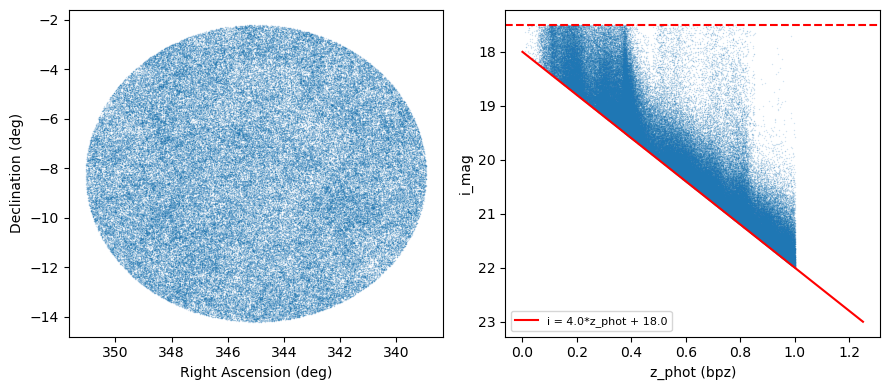

In [8]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9, 4))

ax1.plot(galaxies['ra'], galaxies['dec'], 'o', ms=1, mew=0, alpha=0.2, color='tab:blue')
ax1.set_xlabel('Right Ascension (deg)')
ax1.set_ylabel('Declination (deg)')
ax1.invert_xaxis()

ax2.plot(galaxies['z_phot'], galaxies['i_mag'], 'o', ms=1, mew=0, alpha=0.2, color='tab:blue')
z_line = np.linspace(0, (23 - MAGLIM_INTERCEPT) / MAGLIM_SLOPE, 100)
ax2.plot(z_line, MAGLIM_SLOPE * z_line + MAGLIM_INTERCEPT, 'r-', lw=1.5,
         label='i = {}*z_phot + {}'.format(MAGLIM_SLOPE, MAGLIM_INTERCEPT))
ax2.axhline(MAG_BRIGHT, color='r', ls='--', lw=1.5)
ax2.set_xlabel('z_phot ({})'.format(PZ_CODE))
ax2.set_ylabel('i_mag')
ax2.invert_yaxis()
ax2.legend(fontsize=8)

plt.tight_layout()
plt.show()


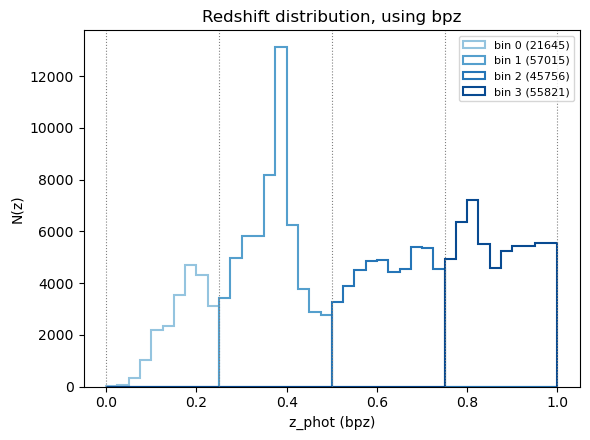

In [9]:
fig, ax = plt.subplots(figsize=(6, 4.5))
zbin_blues = plt.cm.Blues(np.linspace(0.4, 0.9, N_ZBINS))
z_bins_fine = np.linspace(Z_EDGES[0], Z_EDGES[-1], 41)
for b in range(N_ZBINS):
    sel = galaxies['zbin'] == b
    ax.hist(galaxies['z_phot'][sel], bins=z_bins_fine, histtype='step', lw=1.5, color=zbin_blues[b],
           label='bin {} ({})'.format(b, int(sel.sum())))
for edge in Z_EDGES:
    ax.axvline(edge, color='grey', ls=':', lw=0.8)
ax.set_xlabel('z_phot ({})'.format(PZ_CODE))
ax.set_ylabel('N(z)')
ax.set_title('Redshift distribution, using {}'.format(PZ_CODE))
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()


<div class="alert alert-block alert-warning">
<b>Questions: the MagLim sample and tomographic bins</b>

2a. The MagLim cut rises with photo-z, `i < 4*z_phot + 18`, rather than using one fixed magnitude limit. What would a single flat magnitude cut do to the number of galaxies in the highest-redshift bin compared to the lowest one?<br>
2b. Consider the n(z), the number of galaxies per unit redshift. For a magnitude-limited sample, would you expect n(z) to rise, fall, or stay flat with redshift? What two competing effects control that trend?<br>
2c. `N_ZBINS = 4` is a choice. What would you gain and lose by using many more, narrower bins instead?<br>
</div>


<div class="alert alert-block alert-info">
<b>Exercise II: does the choice of photo-z algorithm change n(z)?</b>

This notebook picks `PZ_CODE = pz_codes[0]` — whichever estimator sorts first alphabetically
(`bpz`), with no real justification. DP2's `object_photoz` catalog has several independent
algorithms (`pz_codes` lists them all: `bpz`, `dnf`, `fzboost`, `gpz`, `knn`, `tpz`), each
with its own scatter and outlier behavior.

Re-open `object_photoz` (as in Section 2.2) but request a second point-estimate column too —
this notebook's `pz_col` and a second algorithm's `..._z_median` column — cone-search and join
exactly as before, apply the same MagLim-style cut (Section 2.3) using *each* photo-z in turn,
and plot the resulting n(z) next to the one above. A scatter plot of one algorithm's z_phot
against the other's, for the shared galaxy sample, is a good companion figure.

*Guiding questions:*<br>
IIa. Do the two algorithms agree well across the bulk of the sample, or mostly at the bright end? Where do they diverge most?<br>
IIb. Does switching algorithms change which galaxies pass the MagLim cut at all (since the cut itself uses z_phot), not just which tomographic bin they land in?<br>
IIc. If this notebook used the other algorithm throughout, would you expect the redshift evolution trend in Section 4.5 to look stronger, weaker, or about the same? Why?<br>
</div>


In [10]:
# TODO: open object_photoz with columns=['objectId', 'ra', 'dec', pz_col, OTHER_pz_col],
# join to obj_cat as in Section 2.2, apply the MagLim cut (Section 2.3) using each photo-z
# column in turn, and plot both n(z) histograms + a z1-vs-z2 scatter for the shared sample.


## 3. Masking and systematics templates

A galaxy that's harder to detect because of poor seeing, shallow depth, or a nearby bright
star isn't missing for any physical reason — but if that effect varies smoothly across the
sky, it can imprint a density trend that looks exactly like real large-scale structure, and
bias everything measured downstream of it. Build a footprint mask — the set of sky pixels
where the data are uniform enough to trust — from the DP2 survey property maps (via the
Butler) and a stellar density map built from the Object catalog. The same maps double as
systematics templates: maps of an observational quantity (depth, PSF size, sky noise,
exposure time, stellar density, dust) that can imprint a spurious trend in observed galaxy
density if left uncorrected. We diagnose and correct that trend both here (a linear
per-galaxy weight) and in Section 5 (NaMaster template deprojection), following the general
approach of Rodríguez-Monroy et al. 2022
([arXiv:2105.13540](https://arxiv.org/abs/2105.13540)).


### 3.1. Connect to the Butler

The Butler is the pipelines' interface to the DP2 survey property maps used throughout this section.


In [11]:
butler = Butler("dp2", collections="dp2")


### 3.2. Helper to fetch a region-restricted survey property map

Survey property maps are delivered as all-sky HealSparse files, which are far too large to
read at full resolution. Read only the low-resolution coverage map first, keep the pixels
near the region of interest, and pass those to the Butler so only that cutout is read at
`MASK_NSIDE`.

`get_region_map_cached` wraps this in a disk cache under `MAP_CACHE_DIR`: each region cutout
is written to a local FITS file keyed by dataset, band, and region parameters, so re-running
the notebook with the same parameters only pays the Butler I/O cost once per distinct map.

In [12]:
def angular_sep_deg(ra0, dec0, ra1, dec1):
    ra0, dec0, ra1, dec1 = np.radians(ra0), np.radians(dec0), np.radians(ra1), np.radians(dec1)
    cos_sep = np.sin(dec0) * np.sin(dec1) + np.cos(dec0) * np.cos(dec1) * np.cos(ra1 - ra0)
    return np.degrees(np.arccos(np.clip(cos_sep, -1.0, 1.0)))


def get_region_map(dataset_type, band, nside, ra_center, dec_center, radius_deg):
    """Fetch a Butler consolidated survey-property map, restricted to a cone."""
    cov = butler.get('{}.coverage'.format(dataset_type), band=band, skymap='lsst_cells_v2')
    cov_pix = np.where(cov.coverage_mask)[0]
    cov_ra, cov_dec = hpg.pixel_to_angle(cov.nside_coverage, cov_pix)
    pad_deg = radius_deg + hpg.nside_to_resolution(cov.nside_coverage, units='degrees')
    nearby = angular_sep_deg(ra_center, dec_center, cov_ra, cov_dec) < pad_deg
    region_cov_pix = cov_pix[nearby]
    return butler.get(dataset_type, band=band, skymap='lsst_cells_v2',
                      parameters={'pixels': list(region_cov_pix), 'degrade_nside': nside})


os.makedirs(MAP_CACHE_DIR, exist_ok=True)


def get_region_map_cached(dataset_type, band, nside, ra_center, dec_center, radius_deg):
    """Like get_region_map, but caches the cutout to disk to skip the Butler fetch on reruns."""
    key = '{}_{}_nside{}_ra{:.3f}_dec{:.3f}_r{:.3f}.hsp'.format(
        dataset_type, band, nside, ra_center, dec_center, radius_deg)
    for cache_dir in dict.fromkeys([MAP_CACHE_DIR, os.path.join(SHARED_DATA_DIR, 'maps')]):
        cached_path = os.path.join(cache_dir, key)
        if os.path.exists(cached_path):
            print('  loading from cache ({}): {}'.format(cache_dir, key))
            return healsparse.HealSparseMap.read(cached_path)
    path = os.path.join(MAP_CACHE_DIR, key)
    print('  fetching from Butler:', key)
    hspmap = get_region_map(dataset_type, band, nside, ra_center, dec_center, radius_deg)
    hspmap.write(path, clobber=True)
    return hspmap


### 3.3. Fetch the survey property maps

The mask itself only strictly needs `psf_maglim` (the depth cut) and the `griz` coverage
check; the other three maps (`psf_size`, `sky_noise`, `exposure_time`) feed the systematics
diagnostics and weights (Section 3.6) and the power-spectrum template deprojection
(Section 5). We fetch all seven maps up front — every fetch is cached to disk (Section 3.2),
so this only costs real Butler I/O once. Coverage in `g`, `r`, `z` is checked using the same
`psf_maglim` dataset in each band (a measured value means coverage).


In [13]:
DEPTH_LIMIT_I = MAGLIM_SLOPE * Z_EDGES[-1] + MAGLIM_INTERCEPT + DEPTH_MARGIN_MAG
print('Requiring i-band depth deeper than {:.2f} mag ({:.1f} mag beyond the sample faint limit)'
      .format(DEPTH_LIMIT_I, DEPTH_MARGIN_MAG))

maglim_map = get_region_map_cached('deepCoadd_psf_maglim_consolidated_map_weighted_mean', BAND,
                                   MASK_NSIDE, RA_CENTER, DEC_CENTER, RADIUS_DEG)
psfsize_map = get_region_map_cached('deepCoadd_psf_size_consolidated_map_weighted_mean', BAND,
                                    MASK_NSIDE, RA_CENTER, DEC_CENTER, RADIUS_DEG)
skynoise_map = get_region_map_cached('deepCoadd_sky_noise_consolidated_map_weighted_mean', BAND,
                                     MASK_NSIDE, RA_CENTER, DEC_CENTER, RADIUS_DEG)
exptime_map = get_region_map_cached('deepCoadd_exposure_time_consolidated_map_sum', BAND,
                                    MASK_NSIDE, RA_CENTER, DEC_CENTER, RADIUS_DEG)
other_bands = [b for b in ['g', 'r', 'i', 'z'] if b != BAND]
coverage_maps = {b: get_region_map_cached('deepCoadd_psf_maglim_consolidated_map_weighted_mean', b,
                                          MASK_NSIDE, RA_CENTER, DEC_CENTER, RADIUS_DEG)
                 for b in other_bands}
print('Fetched all 7 survey property maps')


Requiring i-band depth deeper than 23.00 mag (1.0 mag beyond the sample faint limit)
  loading from cache: deepCoadd_psf_maglim_consolidated_map_weighted_mean_i_nside4096_ra345.000_dec-8.200_r6.000.hsp
  loading from cache: deepCoadd_psf_size_consolidated_map_weighted_mean_i_nside4096_ra345.000_dec-8.200_r6.000.hsp
  loading from cache: deepCoadd_sky_noise_consolidated_map_weighted_mean_i_nside4096_ra345.000_dec-8.200_r6.000.hsp
  loading from cache: deepCoadd_exposure_time_consolidated_map_sum_i_nside4096_ra345.000_dec-8.200_r6.000.hsp
  loading from cache: deepCoadd_psf_maglim_consolidated_map_weighted_mean_g_nside4096_ra345.000_dec-8.200_r6.000.hsp
  loading from cache: deepCoadd_psf_maglim_consolidated_map_weighted_mean_r_nside4096_ra345.000_dec-8.200_r6.000.hsp
  loading from cache: deepCoadd_psf_maglim_consolidated_map_weighted_mean_z_nside4096_ra345.000_dec-8.200_r6.000.hsp
Fetched all 7 survey property maps


### 3.4. Build the mask

Pixelize the query region, evaluate the depth and coverage cuts plus a stellar-density veto at each pixel, and combine them into one boolean mask that we then apply to the galaxy sample.


In [14]:
def pixels_at(ra, dec, nside=MASK_NSIDE):
    return hp.ang2pix(nside, np.asarray(ra), np.asarray(dec), nest=True, lonlat=True)


def count_in_pixels(ra, dec, pix_grid):
    pix = pixels_at(ra, dec)
    idx = np.clip(np.searchsorted(pix_grid, pix), 0, len(pix_grid) - 1)
    found = pix_grid[idx] == pix
    counts = np.zeros(len(pix_grid))
    np.add.at(counts, idx[found], 1)
    return counts


mask_vec = hp.ang2vec(RA_CENTER, DEC_CENTER, lonlat=True)
mask_pix = np.sort(hp.query_disc(MASK_NSIDE, mask_vec, np.radians(RADIUS_DEG), nest=True))
mask_ra, mask_dec = hp.pix2ang(MASK_NSIDE, mask_pix, nest=True, lonlat=True)
pixel_area_deg2 = hp.nside2pixarea(MASK_NSIDE, degrees=True)
print('{} candidate pixels at nside={} ({:.6f} deg^2 each)'.format(
    len(mask_pix), MASK_NSIDE, pixel_area_deg2))

i_maglim_vals = maglim_map.get_values_pos(mask_ra, mask_dec)
i_psfsize_vals = psfsize_map.get_values_pos(mask_ra, mask_dec)
i_skynoise_vals = skynoise_map.get_values_pos(mask_ra, mask_dec)
i_exptime_vals = exptime_map.get_values_pos(mask_ra, mask_dec)

coverage_ok = np.ones(len(mask_pix), dtype=bool)
for b, m in coverage_maps.items():
    coverage_ok &= (m.get_values_pos(mask_ra, mask_dec) > 0)


551467 candidate pixels at nside=4096 (0.000205 deg^2 each)


In [15]:
star_columns = ['coord_ra', 'coord_dec']
star_query = (
    "SELECT " + ", ".join(star_columns) + " "
    "FROM dp2.Object "
    "WHERE CONTAINS(POINT('ICRS', coord_ra, coord_dec), "
    "CIRCLE('ICRS', {ra}, {dec}, {radius})) = 1 "
    "AND refExtendedness = 0 "
    "AND {b}_inputCount > 0 "
    "AND {b}_psfFlux_flag = 0 "
    "AND {b}_invalidPsfFlag = 0 "
    "AND {b}_pixelFlags_saturatedCenter = 0 "
    "AND {b}_pixelFlags_interpolatedCenter = 0 "
    "AND {b}_psfMag > {bright} "
    "AND {b}_psfMag < {faint}"
).format(ra=RA_CENTER, dec=DEC_CENTER, radius=RADIUS_DEG, b=BAND,
         bright=STAR_MAG_BRIGHT, faint=STAR_MAG_FAINT)
star_df = run_query(star_query).to_pandas()
print(len(star_df), 'point sources for the stellar density map')

star_counts = count_in_pixels(star_df['coord_ra'].values, star_df['coord_dec'].values, mask_pix)
star_density = star_counts / pixel_area_deg2
density_thresh = np.percentile(star_density[coverage_ok], STELLAR_DENSITY_PERCENTILE)
low_stellar_density = star_density <= density_thresh
print('Stellar density veto threshold ({:.0f}th pct): {:.1f} stars/deg^2'.format(
    STELLAR_DENSITY_PERCENTILE, density_thresh))


Job phase is COMPLETED
354050 point sources for the stellar density map
Stellar density veto threshold (90th pct): 9760.6 stars/deg^2


In [16]:
valid_mask = (i_maglim_vals > DEPTH_LIMIT_I) & coverage_ok & low_stellar_density
valid_pix = mask_pix[valid_mask]
mask_area_deg2 = valid_mask.sum() * pixel_area_deg2
print('{} of {} pixels pass the mask ({:.1f}%), unmasked area {:.2f} deg^2'.format(
    valid_mask.sum(), len(mask_pix), 100 * valid_mask.mean(), mask_area_deg2))


def in_mask(ra, dec):
    pix = pixels_at(ra, dec)
    idx = np.clip(np.searchsorted(valid_pix, pix), 0, len(valid_pix) - 1)
    return valid_pix[idx] == pix


galaxies = galaxies.loc[in_mask(galaxies['ra'].values, galaxies['dec'].values)].reset_index(drop=True)
print(len(galaxies), 'galaxies remain after the mask')
for b in range(N_ZBINS):
    print('  bin {}: {} galaxies'.format(b, np.sum(galaxies['zbin'] == b)))


534571 of 551467 pixels pass the mask (96.9%), unmasked area 109.54 deg^2
174701 galaxies remain after the mask
  bin 0: 20973 galaxies
  bin 1: 55329 galaxies
  bin 2: 44254 galaxies
  bin 3: 54145 galaxies


In [17]:
# Breakdown by individual cut, rather than a spatial plot: with only ~3% of the footprint
# excluded here, a valid/invalid map mostly just shows the circular query boundary, not much
# about *why* pixels are cut. The three conditions are not mutually exclusive.
print('Mask breakdown ({} candidate pixels):'.format(len(mask_pix)))
print('  depth < {:.2f} mag:     {:.1%} of pixels'.format(
    DEPTH_LIMIT_I, np.mean(i_maglim_vals <= DEPTH_LIMIT_I)))
print('  missing griz coverage:  {:.1%} of pixels'.format(np.mean(~coverage_ok)))
print('  high stellar density:   {:.1%} of pixels'.format(np.mean(~low_stellar_density)))
print('  combined mask removes:  {:.1%} of pixels ({:.2f} of {:.2f} deg^2 kept)'.format(
    np.mean(~valid_mask), mask_area_deg2, len(mask_pix) * pixel_area_deg2))


Mask breakdown (551467 candidate pixels):
  depth < 23.00 mag:     0.0% of pixels
  missing griz coverage:  0.2% of pixels
  high stellar density:   2.9% of pixels
  combined mask removes:  3.1% of pixels (109.54 of 113.00 deg^2 kept)


<div class="alert alert-block alert-warning">
<b>Questions: the mask</b>

3.4a. The breakdown above is in terms of the *fraction of candidate pixels* removed by each cut. Is that the same as the fraction of *galaxies* removed? Why might the two differ?<br>
3.4b. The randoms generated in Section 4.1 are drawn only from `valid_pix`. What would happen to w(θ) if the randoms ignored the mask but the galaxies didn't?<br>
</div>


### 3.5. Build the systematics templates

Pixelize each systematic at `DIAG_NSIDE` (256-512): the i-band Butler maps, stellar density,
and E(B-V), which has no dedicated Butler map so it is built here by averaging the per-object
`ebv` column (pulled with the Object query) in each pixel.

In [18]:
def weighted_sum_in_pixels(ra, dec, values, pix_grid):
    pix = pixels_at(ra, dec)
    idx = np.clip(np.searchsorted(pix_grid, pix), 0, len(pix_grid) - 1)
    found = pix_grid[idx] == pix
    sums = np.zeros(len(pix_grid))
    counts = np.zeros(len(pix_grid))
    np.add.at(sums, idx[found], values[found])
    np.add.at(counts, idx[found], 1)
    return sums, counts


ebv_sum, ebv_count = weighted_sum_in_pixels(obj_df_renamed['ra'].values, obj_df_renamed['dec'].values,
                                            obj_df_renamed['ebv'].values, mask_pix)
with np.errstate(invalid='ignore', divide='ignore'):
    ebv_native = np.where(ebv_count > 0, ebv_sum / np.maximum(ebv_count, 1), np.nan)

systematic_labels = {
    'i_depth': 'i-band depth (maglim)',
    'ebv': 'E(B-V)',
    'stellar_density': 'stellar density (/deg^2)',
    'i_psf_size': 'i-band PSF size',
    'i_sky_noise': 'i-band sky noise',
    'i_exptime': 'i-band exposure time',
}
systematics_native = {
    'i_depth': i_maglim_vals,
    'ebv': ebv_native,
    'stellar_density': star_density,
    'i_psf_size': i_psfsize_vals,
    'i_sky_noise': i_skynoise_vals,
    'i_exptime': i_exptime_vals,
}
print('Systematics templates:', list(systematic_labels.keys()))

systematics_valid = {k: v[valid_mask] for k, v in systematics_native.items()}


def degrade_pix(pix_fine, nside_fine, nside_coarse):
    shift = 2 * int(round(np.log2(nside_fine / nside_coarse)))
    return pix_fine >> shift


diag_pix_of_valid = degrade_pix(valid_pix, MASK_NSIDE, DIAG_NSIDE)
diag_unique, diag_inverse = np.unique(diag_pix_of_valid, return_inverse=True)
diag_area_deg2 = hp.nside2pixarea(DIAG_NSIDE, degrees=True)


def mean_per_diag_pixel(values):
    valid = ~np.isnan(values)
    sums = np.bincount(diag_inverse[valid], weights=values[valid], minlength=len(diag_unique))
    counts = np.bincount(diag_inverse[valid], minlength=len(diag_unique))
    with np.errstate(invalid='ignore', divide='ignore'):
        return np.where(counts > 0, sums / np.maximum(counts, 1), np.nan)


diag_values = {name: mean_per_diag_pixel(systematics_valid[name]) for name in systematic_labels}
valid_native_count_diag = np.bincount(diag_inverse, minlength=len(diag_unique))
diag_area_per_pix_deg2 = valid_native_count_diag * pixel_area_deg2


Systematics templates: ['i_depth', 'ebv', 'stellar_density', 'i_psf_size', 'i_sky_noise', 'i_exptime']


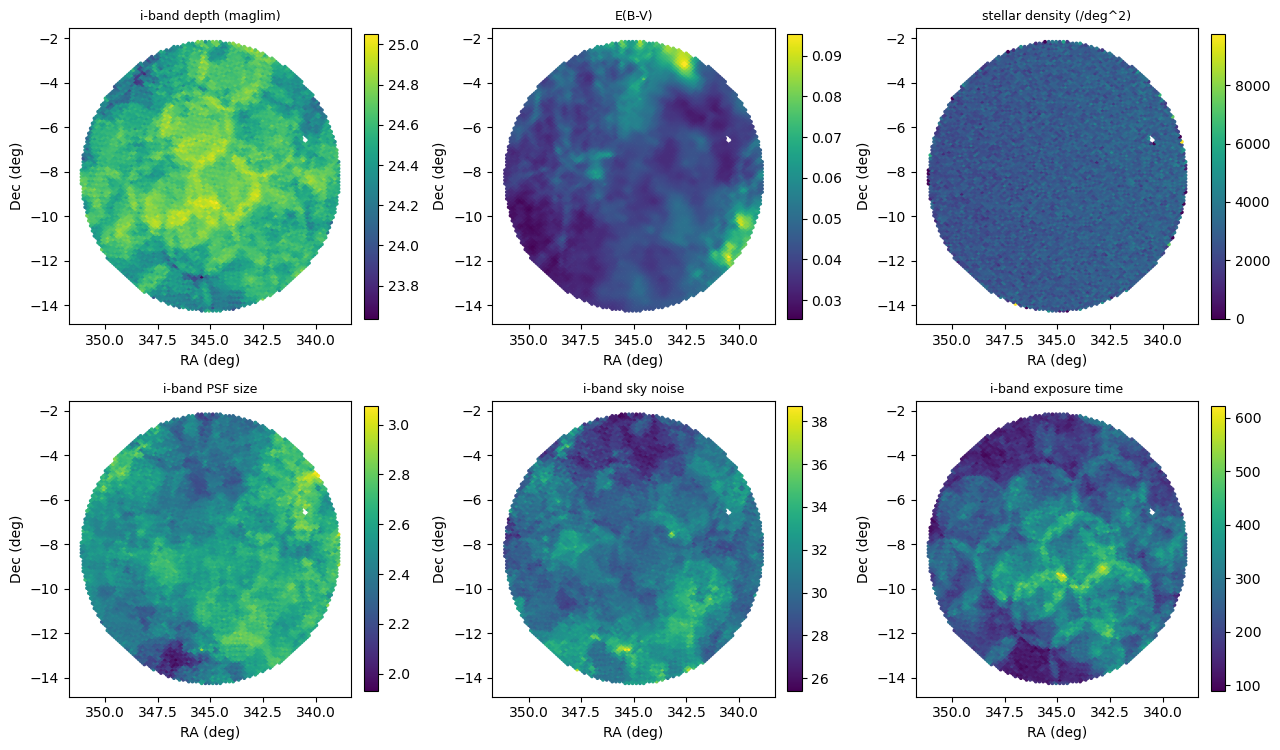

In [19]:
n_sys = len(systematic_labels)
ncols = min(3, n_sys)
nrows = int(np.ceil(n_sys / ncols))
diag_ra, diag_dec = hp.pix2ang(DIAG_NSIDE, diag_unique, nest=True, lonlat=True)

fig, axes = plt.subplots(nrows, ncols, figsize=(4.3 * ncols, 3.8 * nrows), squeeze=False)
axes = axes.flatten()
for ax, (name, label) in zip(axes, systematic_labels.items()):
    sc = ax.scatter(diag_ra, diag_dec, c=diag_values[name], s=3, cmap='viridis')
    ax.invert_xaxis()
    ax.set_xlabel('RA (deg)')
    ax.set_ylabel('Dec (deg)')
    ax.set_title(label, fontsize=9)
    fig.colorbar(sc, ax=ax, fraction=0.046, pad=0.04)
for ax in axes[n_sys:]:
    ax.set_visible(False)
plt.tight_layout()
plt.show()


In [20]:
def galaxy_density_diag(sel=None):
    """Per-diagnostic-pixel galaxy count and mean density, optionally for a boolean subset
    of `galaxies` (e.g. one tomographic bin); reused for the full sample here and per-bin
    in Section 5."""
    ra = galaxies['ra'].values if sel is None else galaxies['ra'][sel].values
    dec = galaxies['dec'].values if sel is None else galaxies['dec'][sel].values
    counts_native = count_in_pixels(ra, dec, mask_pix)
    counts_native_valid = counts_native[valid_mask]
    n_gal = np.bincount(diag_inverse, weights=counts_native_valid, minlength=len(diag_unique))
    mean_dens = n_gal.sum() / diag_area_per_pix_deg2.sum()
    return n_gal, mean_dens


n_gal_diag, mean_density = galaxy_density_diag()
print('Mean galaxy density: {:.2f} / deg^2 over {} diagnostic pixels at nside={}'.format(
    mean_density, len(diag_unique), DIAG_NSIDE))

N_SYS_BINS = 8


def density_ratio_trend(sys_values, n_gal, area, mean_dens, nbins=N_SYS_BINS):
    """n_gal/<n_gal> in nbins percentile bins of a systematic, for the classic DES figure."""
    good = ~np.isnan(sys_values) & (area > 0)
    edges = np.nanpercentile(sys_values[good], np.linspace(0, 100, nbins + 1))
    edges[0] -= 1e-6
    edges[-1] += 1e-6
    bin_idx = np.clip(np.digitize(sys_values[good], edges) - 1, 0, nbins - 1)
    x, y, yerr = [], [], []
    for k in range(nbins):
        sel = bin_idx == k
        if not np.any(sel):
            continue
        n_tot = n_gal[good][sel].sum()
        a_tot = area[good][sel].sum()
        dens = (n_tot / a_tot) / mean_dens
        err = dens / np.sqrt(max(n_tot, 1))
        x.append(np.average(sys_values[good][sel]))
        y.append(dens)
        yerr.append(err)
    return np.array(x), np.array(y), np.array(yerr)


Mean galaxy density: 1594.91 / deg^2 over 8797 diagnostic pixels at nside=512


### 3.6. Fit systematics weights

Fit a linear model for the fractional overdensity in terms of the (standardized)
systematics at `DIAG_NSIDE`, weighted by the unmasked area per diagnostic pixel. Each
galaxy's weight is `1 / (1 + sum_i a_i * s_i)`, evaluated at its own position. The plot below
compares the `n_gal / <n>` trend before and after weighting, for each systematic — the
classic DES validation figure, shown once with both curves rather than twice.

In [21]:
sys_names = list(systematic_labels.keys())
X_raw = np.column_stack([diag_values[name] for name in sys_names])
good = (diag_area_per_pix_deg2 > 0) & ~np.isnan(X_raw).any(axis=1)

X_mean = X_raw[good].mean(axis=0)
X_std = X_raw[good].std(axis=0)
X_std[X_std == 0] = 1.0
X_norm = (X_raw - X_mean) / X_std

y = (n_gal_diag / diag_area_per_pix_deg2) / mean_density - 1.0
area_weight = diag_area_per_pix_deg2

A = X_norm[good] * np.sqrt(area_weight[good])[:, None]
b_ = y[good] * np.sqrt(area_weight[good])
coeffs, _, _, _ = np.linalg.lstsq(A, b_, rcond=None)
print('Fitted systematics coefficients:')
for name, c in zip(sys_names, coeffs):
    print('  {:<16s} {:+.4f}'.format(name, c))


Fitted systematics coefficients:
  i_depth          +0.0152
  ebv              -0.0203
  stellar_density  -0.0091
  i_psf_size       -0.0056
  i_sky_noise      +0.0345
  i_exptime        -0.0237


In [22]:
def lookup_valid(values_at_valid_pix, ra, dec):
    pix = pixels_at(ra, dec)
    idx = np.clip(np.searchsorted(valid_pix, pix), 0, len(valid_pix) - 1)
    found = valid_pix[idx] == pix
    out = np.full(len(pix), np.nan)
    out[found] = values_at_valid_pix[idx[found]]
    return out


gal_ra = galaxies['ra'].values
gal_dec = galaxies['dec'].values
gal_sys = {
    'i_depth': maglim_map.get_values_pos(gal_ra, gal_dec),
    'ebv': galaxies['ebv'].values,
    'stellar_density': lookup_valid(systematics_valid['stellar_density'], gal_ra, gal_dec),
    'i_psf_size': psfsize_map.get_values_pos(gal_ra, gal_dec),
    'i_sky_noise': skynoise_map.get_values_pos(gal_ra, gal_dec),
    'i_exptime': exptime_map.get_values_pos(gal_ra, gal_dec),
}
X_gal = np.column_stack([gal_sys[name] for name in sys_names])
X_gal_norm = (X_gal - X_mean) / X_std
model = 1.0 + X_gal_norm @ coeffs
galaxies['weight'] = 1.0 / np.clip(model, 0.5, 2.0)
print('Weight stats: min {:.3f}, max {:.3f}, mean {:.3f}'.format(
    galaxies['weight'].min(), galaxies['weight'].max(), galaxies['weight'].mean()))


Weight stats: min 0.710, max 1.340, mean 1.003


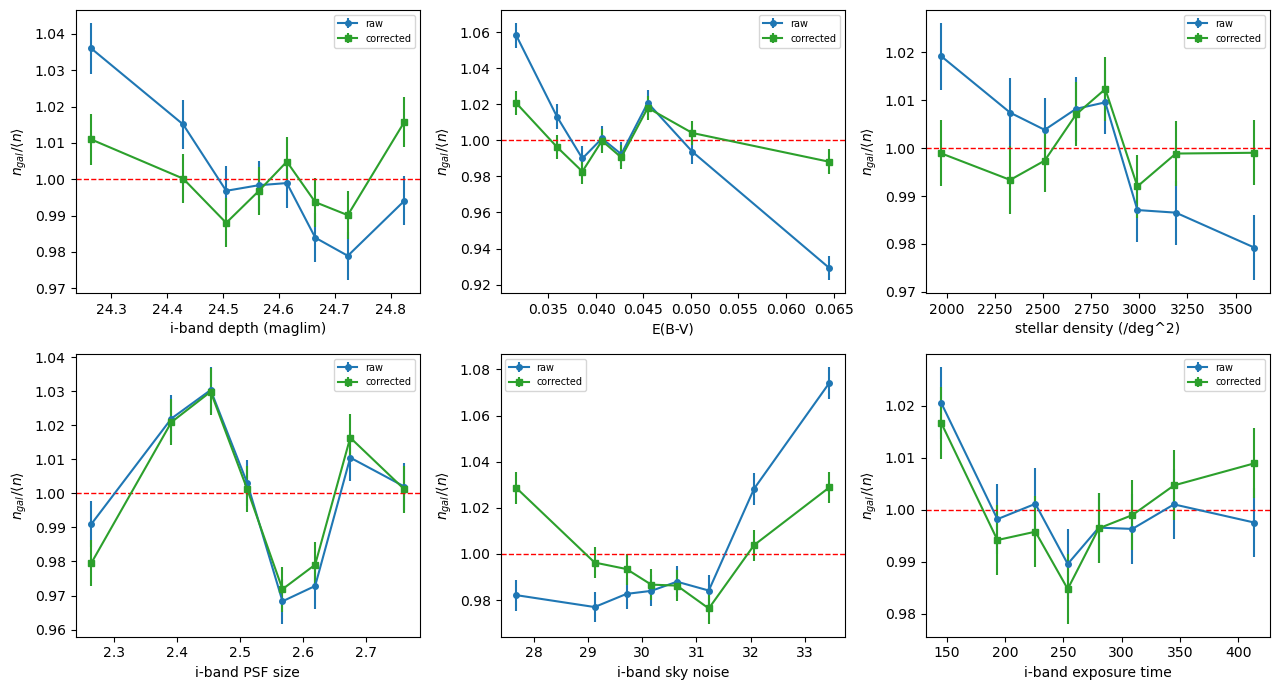

In [23]:
gal_weight_full = np.zeros(len(mask_pix))
pix = pixels_at(gal_ra, gal_dec)
idx = np.clip(np.searchsorted(mask_pix, pix), 0, len(mask_pix) - 1)
found = mask_pix[idx] == pix
np.add.at(gal_weight_full, idx[found], galaxies['weight'].values[found])
gal_weight_valid = gal_weight_full[valid_mask]
n_gal_diag_w = np.bincount(diag_inverse, weights=gal_weight_valid, minlength=len(diag_unique))
mean_density_w = n_gal_diag_w.sum() / diag_area_per_pix_deg2.sum()

n_sys = len(systematic_labels)
ncols = min(3, n_sys)
nrows = int(np.ceil(n_sys / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(4.3 * ncols, 3.5 * nrows), squeeze=False)
axes = axes.flatten()
for ax, (name, label) in zip(axes, systematic_labels.items()):
    x_r, y_r, yerr_r = density_ratio_trend(diag_values[name], n_gal_diag, diag_area_per_pix_deg2, mean_density)
    x_w, y_w, yerr_w = density_ratio_trend(diag_values[name], n_gal_diag_w, diag_area_per_pix_deg2, mean_density_w)
    ax.errorbar(x_r, y_r, yerr=yerr_r, fmt='o-', ms=4, color='tab:blue', label='raw')
    ax.errorbar(x_w, y_w, yerr=yerr_w, fmt='s-', ms=4, color='tab:green', label='corrected')
    ax.axhline(1.0, color='r', ls='--', lw=1)
    ax.set_xlabel(label)
    ax.set_ylabel(r'$n_{gal}/\langle n \rangle$')
    ax.legend(fontsize=7)
for ax in axes[n_sys:]:
    ax.set_visible(False)
plt.tight_layout()
plt.show()


<div class="alert alert-block alert-info">
<b>Exercise III: rank the systematics by importance</b>

Section 3.6 fits one coefficient per systematic simultaneously. Some systematics likely
matter much more than others for this particular mask and depth.

Refit the model leaving out one systematic at a time (drop it from `sys_names` and rebuild
`X_norm`/`X_gal_norm`, or just zero its fitted coefficient before applying the weight), and
compare the resulting `n_gal/<n>` trend (the Section 3.6 plot) with and without that
systematic's own correction term. Rank the six systematics by how much including them changes
the density trend.

*Guiding questions:*<br>
IIIa. Which single systematic's correction matters most for this mask and depth? Does that match what you'd guess from the Section 3.5 maps (which one has the most spatial structure over the footprint)?<br>
IIIb. Two systematics can be correlated with each other (for example, exposure time and sky noise). Does removing one from the fit change the fitted coefficient of the other? What does that tell you about disentangling them?<br>
IIIc. Would you expect the ranking to change with a deeper (fainter) MagLim sample? Why or why not?<br>
</div>


In [24]:
# TODO: for each name in sys_names, refit coeffs with that systematic dropped (or its
# coefficient zeroed), recompute the weight, and replot density_ratio_trend for that one
# systematic with vs. without its own correction term. Rank by how much the trend flattens.


## 4. Angular correlation function

The angular correlation function w(θ) measures the excess probability, over a random
distribution, of finding two galaxies separated by angle θ — a positive w(θ) means galaxies
cluster together more than chance would predict, exactly what you'd expect if galaxies trace
a biased version of the underlying dark matter. Generate randoms matching the mask, then
measure the raw and weighted w(theta) per tomographic bin with TreeCorr.


### 4.1. Randoms

A correlation function needs a baseline for "no clustering" that still has the same survey
geometry as the data — a catalog of points with the same mask and footprint, but no physical
clustering. Randoms serve that role. We generate them uniformly over the unmasked footprint:
pick a random valid `MASK_NSIDE` pixel, then jitter to a random sub-pixel position
`RAND_OVERSAMPLE` times finer, which approximates continuous uniform sampling within the
pixel. The same random catalog is reused for every tomographic bin, since the mask does not
depend on redshift.


In [25]:
N_RANDOMS = min(MAX_RANDOMS, RAND_FACTOR * len(galaxies))
RAND_OVERSAMPLE = 16
rand_nside = MASK_NSIDE * RAND_OVERSAMPLE
sub_factor2 = RAND_OVERSAMPLE**2

rng = np.random.default_rng(0)
chosen_coarse = valid_pix[rng.integers(0, len(valid_pix), size=N_RANDOMS)]
sub_offset = rng.integers(0, sub_factor2, size=N_RANDOMS)
fine_pix = chosen_coarse.astype(np.int64) * sub_factor2 + sub_offset
rand_ra, rand_dec = hp.pix2ang(rand_nside, fine_pix, nest=True, lonlat=True)
print(N_RANDOMS, 'randoms generated ({:.1f}x the galaxy count)'.format(N_RANDOMS / len(galaxies)))


2000000 randoms generated (11.4x the galaxy count)


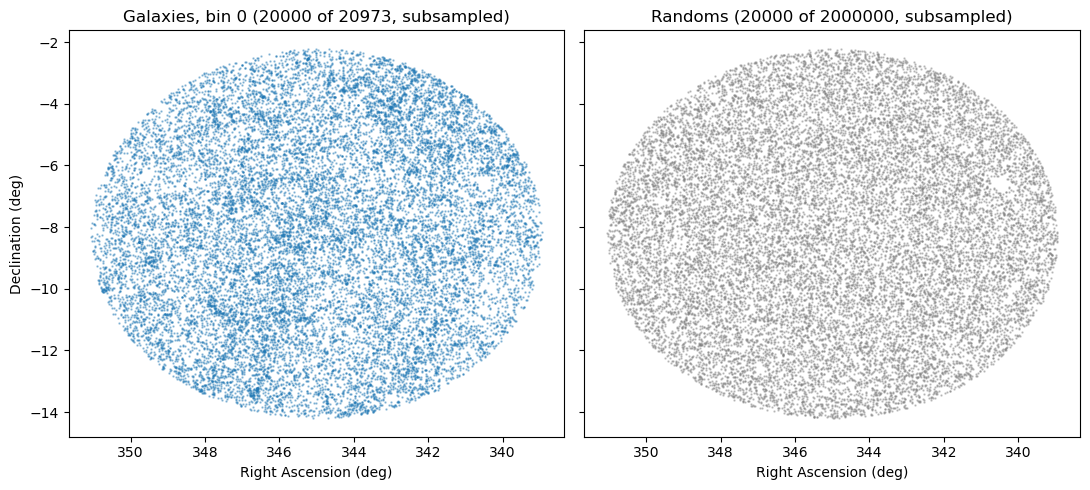

In [26]:
EXAMPLE_ZBIN = 0
N_PLOT_SUB = 20000

rng_plot = np.random.default_rng(1)
rand_sub = rng_plot.choice(len(rand_ra), size=min(N_PLOT_SUB, len(rand_ra)), replace=False)

gal_sel = (galaxies['zbin'] == EXAMPLE_ZBIN).values
gal_ra_bin = galaxies['ra'][gal_sel].values
gal_dec_bin = galaxies['dec'][gal_sel].values
gal_sub = rng_plot.choice(len(gal_ra_bin), size=min(N_PLOT_SUB, len(gal_ra_bin)), replace=False)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 5), sharex=True, sharey=True)
ax1.plot(gal_ra_bin[gal_sub], gal_dec_bin[gal_sub], '.', ms=1.5, alpha=0.4, color='tab:blue')
ax1.set_title('Galaxies, bin {} ({} of {}, subsampled)'.format(
    EXAMPLE_ZBIN, len(gal_sub), len(gal_ra_bin)))
ax1.set_xlabel('Right Ascension (deg)')
ax1.set_ylabel('Declination (deg)')
ax1.invert_xaxis()

ax2.plot(rand_ra[rand_sub], rand_dec[rand_sub], '.', ms=1.5, alpha=0.4, color='grey')
ax2.set_title('Randoms ({} of {}, subsampled)'.format(len(rand_sub), N_RANDOMS))
ax2.set_xlabel('Right Ascension (deg)')
plt.tight_layout()
plt.show()

### 4.2. Compute w(theta), raw and weighted

Landy-Szalay estimator, `w = (DD - 2*DR + RR) / RR`, per tomographic bin against the shared
random catalog, both unweighted and using the Section 3.6 weight.

The error bars plotted throughout this section are TreeCorr's internal shot-noise estimate
from the pair counts alone (essentially Poisson, `~1/sqrt(DD)`) — they do not include cosmic
variance from measuring a single patch. Don't read too much into bin-to-bin scatter beyond
what they imply, especially at the largest separations, where real analyses would use
jackknife or bootstrap resampling over sub-regions of the footprint instead.

In [27]:
rand_cat = treecorr.Catalog(ra=rand_ra, dec=rand_dec, ra_units='deg', dec_units='deg')
rr = treecorr.NNCorrelation(min_sep=TC_MIN_SEP_ARCMIN, max_sep=TC_MAX_SEP_ARCMIN,
                            nbins=TC_NBINS, sep_units='arcmin')
rr.process(rand_cat)


def compute_wtheta(ra, dec, w=None):
    cat = treecorr.Catalog(ra=ra, dec=dec, w=w, ra_units='deg', dec_units='deg')
    dd = treecorr.NNCorrelation(min_sep=TC_MIN_SEP_ARCMIN, max_sep=TC_MAX_SEP_ARCMIN,
                                nbins=TC_NBINS, sep_units='arcmin')
    dr = treecorr.NNCorrelation(min_sep=TC_MIN_SEP_ARCMIN, max_sep=TC_MAX_SEP_ARCMIN,
                                nbins=TC_NBINS, sep_units='arcmin')
    dd.process(cat)
    dr.process(cat, rand_cat)
    xi, varxi = dd.calculateXi(rr=rr, dr=dr)
    return dd.meanr, xi, np.sqrt(varxi), dd.npairs, dr.npairs


raw_results = {}
weighted_results = {}
for b in range(N_ZBINS):
    sel = (galaxies['zbin'] == b).values
    raw_results[b] = compute_wtheta(galaxies['ra'][sel].values, galaxies['dec'][sel].values)
    theta, xi, err, _, _ = compute_wtheta(galaxies['ra'][sel].values, galaxies['dec'][sel].values,
                                          w=galaxies['weight'][sel].values)
    weighted_results[b] = (theta, xi, err)
    print('bin {}: {} galaxies'.format(b, sel.sum()))


bin 0: 20973 galaxies
bin 1: 55329 galaxies
bin 2: 44254 galaxies
bin 3: 54145 galaxies


### 4.3. Pair counts (DD, DR, RR)

The raw pair counts TreeCorr combines into the Landy-Szalay estimator above, per
tomographic bin. RR is shared across bins since it only depends on the (redshift-independent)
random catalog.

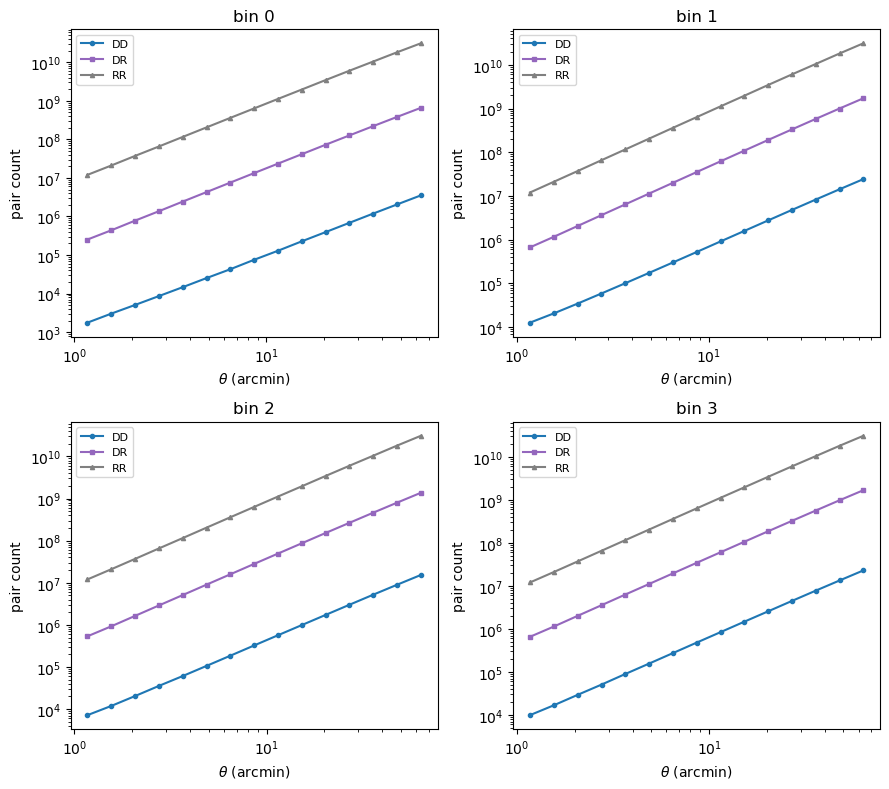

In [28]:
fig, axes = plt.subplots(2, 2, figsize=(9, 8))
axes = axes.flatten()
for b, ax in enumerate(axes):
    theta, xi, err, dd_pairs, dr_pairs = raw_results[b]
    ax.plot(theta, dd_pairs, 'o-', ms=3, color='tab:blue', label='DD')
    ax.plot(theta, dr_pairs, 's-', ms=3, color='tab:purple', label='DR')
    ax.plot(theta, rr.npairs, '^-', ms=3, color='grey', label='RR')
    ax.set_xscale('log')
    ax.set_yscale('log')
    ax.set_title('bin {}'.format(b))
    ax.set_xlabel(r'$\theta$ (arcmin)')
    ax.set_ylabel('pair count')
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()


### 4.4. w(theta): raw vs. weighted

The Section 4.2 measurement, raw and weighted, overlaid per tomographic bin.


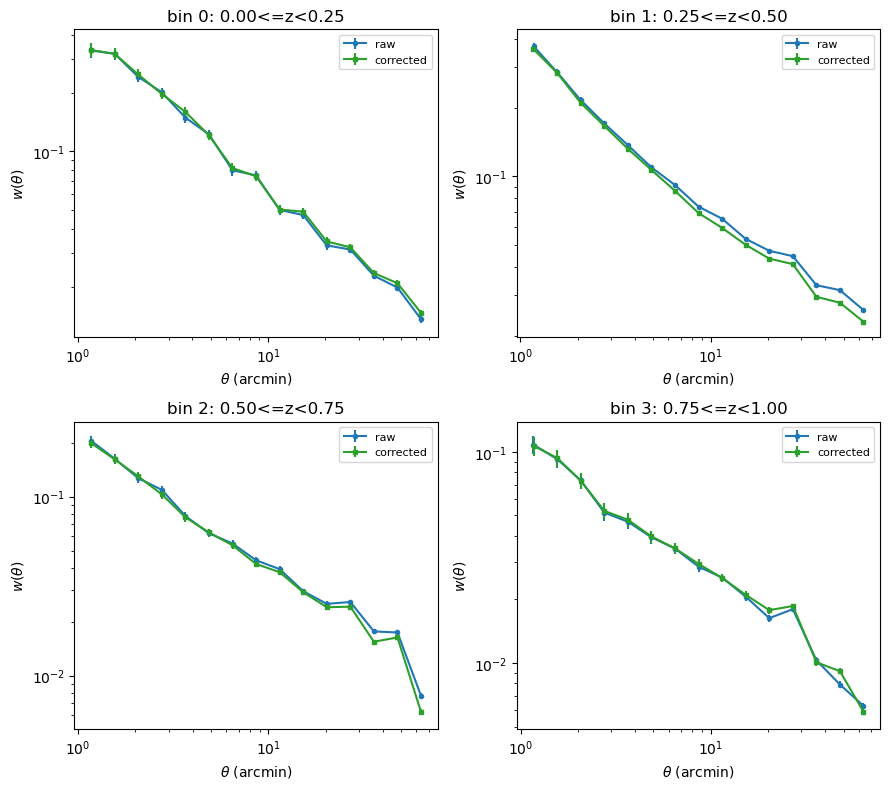

In [29]:
fig, axes = plt.subplots(2, 2, figsize=(9, 8))
axes = axes.flatten()
for b, ax in enumerate(axes):
    theta_r, xi_r, err_r, _, _ = raw_results[b]
    theta_w, xi_w, err_w = weighted_results[b]
    ax.errorbar(theta_r, xi_r, yerr=err_r, fmt='o-', ms=3, color='tab:blue', label='raw')
    ax.errorbar(theta_w, xi_w, yerr=err_w, fmt='s-', ms=3, color='tab:green', label='corrected')
    ax.set_xscale('log')
    ax.set_yscale('log')
    ax.set_title('bin {}: {:.2f}<=z<{:.2f}'.format(b, Z_EDGES[b], Z_EDGES[b + 1]))
    ax.set_xlabel(r'$\theta$ (arcmin)')
    ax.set_ylabel(r'$w(\theta)$')
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()


<div class="alert alert-block alert-warning">
<b>Questions: w(θ), raw vs. weighted</b>

4.4a. At which angular scales does the systematics correction (Section 3.6) change w(θ) the most? Does that match your expectation for where survey-property variations (which vary smoothly over the sky) should matter most?<br>
4.4b. Section 4.2 notes that the plotted error bars are shot-noise only and don't include cosmic variance — the extra scatter from measuring clustering in just one ~113 deg² patch rather than many independent ones. What would adding cosmic variance do to the error bars, and at which angular scales would that matter most relative to shot noise?<br>
4.4c. Independent of the systematics correction, look at the overall shape of w(θ) itself: it declines steeply from small to large θ. Does that shape match what you'd expect for galaxy clustering, and why? (Think about what small versus large angular separation actually probes — pairs within the same dark matter halo versus pairs in different, more weakly correlated halos.)<br>
</div>


### 4.5. Redshift evolution of the corrected w(theta)

The weighted w(theta) from all four tomographic bins, together, to compare clustering shape
and amplitude across redshift directly.

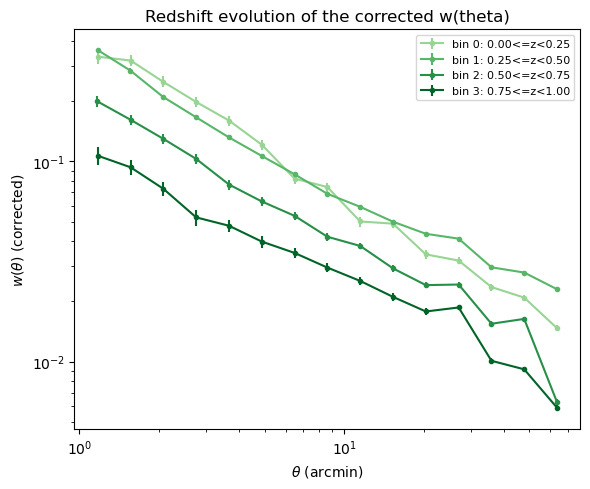

In [30]:
greens_wtheta = plt.cm.Greens(np.linspace(0.4, 0.9, N_ZBINS))
fig, ax = plt.subplots(figsize=(6, 5))
for b in range(N_ZBINS):
    theta, xi, err = weighted_results[b]
    ax.errorbar(theta, xi, yerr=err, fmt='o-', ms=3, color=greens_wtheta[b],
               label='bin {}: {:.2f}<=z<{:.2f}'.format(b, Z_EDGES[b], Z_EDGES[b + 1]))
ax.set_xscale('log')
ax.set_yscale('log')
ax.set_xlabel(r'$\theta$ (arcmin)')
ax.set_ylabel(r'$w(\theta)$ (corrected)')
ax.set_title('Redshift evolution of the corrected w(theta)')
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()


<div class="alert alert-block alert-warning">
<b>Questions: redshift trend in w(θ)</b>

4.5a. How does the amplitude of the corrected w(θ) trend across the four redshift bins — does it rise, fall, or vary non-monotonically with z? Does that trend make sense, given how galaxy bias and the MagLim selection both change with redshift?<br>
</div>


<div class="alert alert-block alert-info">
<b>Exercise IV: cross-bin correlation, a photo-z leakage diagnostic</b>

If two tomographic bins were perfectly separated in true redshift, galaxies in one bin would
live at a different cosmic time/distance than galaxies in the other — there's no physical
reason for their projected positions on the sky to be correlated, so their cross-correlation
$w_{ij}(\theta)$ should be consistent with zero. A nonzero $w_{ij}(\theta)$ is therefore a
direct diagnostic of photo-z bin leakage: galaxies whose true redshift puts them in bin $i$,
but whose photo-z scattered them into bin $j$ (Benjamin et al. 2010; used for a tomographic,
photometric sample much like this one by Coupon et al. 2012, A&A 542, A5,
[arXiv:1107.0616](https://arxiv.org/abs/1107.0616), §3.2 and Fig. 6, who find adjacent-bin
cross-correlations are nonzero while non-adjacent bins are consistent with zero — i.e. most
leakage is into *neighboring* bins, from photo-z scatter, rather than broad outliers).

We measure this with the Landy–Szalay-like cross-correlation estimator
$w_{12} = (D_1D_2 - D_1R - D_2R + RR)/RR$, using TreeCorr's cross-correlation mode and the
same shared random catalog (`rand_cat`, `rr`) from Section 4.2 for both samples.

*Guiding questions:*<br>
IVa. Why is the *same* random catalog (`rand_cat`, `rr`) shared between both samples in this estimator, rather than generating separate randoms for each bin?<br>
IVb. Is the adjacent-bin cross-correlation (bins 0-1) larger than the non-adjacent one (bins 0-3)? Is that consistent with Coupon et al. (2012)'s finding that leakage is dominated by scatter into *neighboring* bins rather than broad outliers?<br>
IVc. If you used more, narrower tomographic bins (`N_ZBINS` larger), would you expect the adjacent-bin leakage to grow, shrink, or stay about the same?<br>
</div>


In [31]:
# TODO: write a cross-correlation version of compute_wtheta (Section 4.2) using
# treecorr.NNCorrelation.process(cat1, cat2) for DD, plus D1-R and D2-R cross terms
# against the shared rand_cat/rr from Section 4.2, combined via dd.calculateXi(rr=rr,
# dr=dr, rd=rd). Compare the cross-correlation between bins 0 and 1 (adjacent) and
# bins 0 and 3 (non-adjacent) to bin 0's auto-correlation (weighted_results[0]).


## 5. Angular power spectrum

A harmonic-space view of the same clustering signal, per tomographic bin: the angular power
spectrum C(ell), raw and with systematics-template deprojection, measured with NaMaster
(proper MASTER-algorithm mode-coupling deconvolution). C(ell) is the harmonic-space transform
of w(theta); ell plays the role of inverse angular scale, so small ell means large angular
scales and large ell means small ones. Real-space and harmonic-space measurements carry the
same information in principle, but behave differently in practice — some systematics are
easier to model and remove in one representation than the other, and comparing the two (as
Exercise VII does for the bias measurement) is itself a useful consistency check.


In [32]:
# Below this ell, the patch is smaller than (or comparable to) the angular scale itself, so
# the mask's own window function dominates over any real signal -- also used as the lower
# edge for the NaMaster bandpowers below.
ELL_MIN = max(2, int(np.ceil(180.0 / (2 * RADIUS_DEG))))
print('ELL_MIN = {} (patch diameter {:.1f} deg)'.format(ELL_MIN, 2 * RADIUS_DEG))


ELL_MIN = 15 (patch diameter 12.0 deg)


### 5.1. Proper deconvolution and template deprojection with NaMaster

[NaMaster](https://namaster.readthedocs.io/) (`pymaster`) does the full MASTER-algorithm
mode-coupling deconvolution properly, and — closer to the point of this comparison — can
deproject contaminant templates directly from the field in harmonic space, the natural
power-spectrum analog of the per-galaxy weight fit in Section 3.6. Reusing the exact same
`diag_values[name]` arrays (same pixelization, same systematics) as that fit keeps the two
treatments as directly comparable as possible. The mode-coupling matrix only depends on the
mask, so it's computed once and reused for every tomographic bin.

`pymaster` is not part of the shared environment; if the import below fails, run
`pip install --user pymaster` once (it builds from source, a couple of minutes) and restart
the kernel.

In [33]:
try:
    import pymaster as nmt
except ImportError:
    raise ImportError(
        "pymaster (NaMaster) is not installed. Run once, in a terminal or a notebook cell:\n"
        "  !pip install --user pymaster\n"
        "then restart the kernel."
    )


def full_map_at_diag(values_at_valid_diag, fill=0.0):
    m = np.full(hp.nside2npix(DIAG_NSIDE), fill)
    m[diag_unique] = np.where(np.isnan(values_at_valid_diag), fill, values_at_valid_diag)
    return m


mask_full_nest = full_map_at_diag(diag_area_per_pix_deg2 / diag_area_deg2)
mask_full_ring = hp.reorder(mask_full_nest, n2r=True)

template_maps_ring = [[hp.reorder(full_map_at_diag(diag_values[name]), n2r=True)]
                      for name in sys_names]
print('Using', len(sys_names), 'contaminant templates:', sys_names)

fsky = np.mean(mask_full_ring)
print('fsky = {:.2e} (1/fsky = {:.0f}) — sets how wide the ell bins need to be below'.format(
    fsky, 1.0 / fsky))


Using 6 contaminant templates: ['i_depth', 'ebv', 'stellar_density', 'i_psf_size', 'i_sky_noise', 'i_exptime']
fsky = 2.66e-03 (1/fsky = 377) — sets how wide the ell bins need to be below


In [34]:
# Linear, uniform-width ell bins look "messy" here: the mode-coupling matrix for a mask this
# small is close to singular, and a few ell ranges (especially near the ELL_MIN cutoff) are
# much less constrained than others, so uniform bins leave some of them numerically unstable
# (wild, often-negative bandpowers) while over-resolving ranges that didn't need it. Binning
# log-spaced in ell matches typical S/N per ell better (fewer, wider bins at low ell; more,
# narrower bins at high ell where there are many more independent modes per unit ell), while
# a minimum-width floor (same `0.08 / fsky` scaling used before) keeps every bin numerically
# stable regardless of where it falls.
NMT_BIN_FLOOR = max(20, int(np.ceil(0.08 / fsky)))
N_LOG_BINS = 16
lmax = 3 * DIAG_NSIDE - 1

raw_edges = np.unique(np.round(np.geomspace(ELL_MIN, lmax + 1, N_LOG_BINS + 1)).astype(int))
edges = [raw_edges[0]]
for e in raw_edges[1:]:
    if e - edges[-1] >= NMT_BIN_FLOOR:
        edges.append(e)
if edges[-1] != raw_edges[-1]:
    edges[-1] = raw_edges[-1]
edges = np.array(edges)

nmt_bins = nmt.NmtBin.from_edges(edges[:-1], edges[1:])
ell_nmt = nmt_bins.get_effective_ells()

# The mode-coupling matrix depends only on the mask, not on any particular field's data, so
# build it once from a placeholder field and reuse it for every tomographic bin below.
field_for_matrix = nmt.NmtField(mask_full_ring, [np.zeros_like(mask_full_ring)], spin=0)
workspace = nmt.NmtWorkspace()
workspace.compute_coupling_matrix(field_for_matrix, field_for_matrix, nmt_bins)

print('{} log-spaced bandpowers (floor width {}) from ell={} to ell={}'.format(
    nmt_bins.get_n_bands(), NMT_BIN_FLOOR, edges[0], edges[-1]))


11 log-spaced bandpowers (floor width 31) from ell=15 to ell=1536


In [35]:
cl_raw_zbins = {}
cl_deproj_zbins = {}
for b in range(N_ZBINS):
    sel = (galaxies['zbin'] == b).values
    n_gal_b, mean_density_b = galaxy_density_diag(sel)
    delta_b_nest = full_map_at_diag((n_gal_b / diag_area_per_pix_deg2) / mean_density_b - 1.0)
    delta_b_ring = hp.reorder(delta_b_nest, n2r=True)

    field_b_plain = nmt.NmtField(mask_full_ring, [delta_b_ring], spin=0)
    cl_raw_zbins[b] = workspace.decouple_cell(nmt.compute_coupled_cell(field_b_plain, field_b_plain))[0]

    field_b_deproj = nmt.NmtField(mask_full_ring, [delta_b_ring], spin=0, templates=template_maps_ring)
    cl_deproj_zbins[b] = workspace.decouple_cell(
        nmt.compute_coupled_cell(field_b_deproj, field_b_deproj))[0]

    frac_neg = np.mean(cl_deproj_zbins[b] < 0)
    print('bin {}: {} galaxies{}'.format(b, sel.sum(),
         ' -- Warning: {:.0%} of deprojected bandpowers negative'.format(frac_neg)
         if frac_neg > 0.1 else ''))


bin 0: 20973 galaxies
bin 1: 55329 galaxies
bin 2: 44254 galaxies
bin 3: 54145 galaxies


### 5.2. C(ell): raw vs. corrected

The Section 5.1 bandpowers, raw and template-deprojected, overlaid per tomographic bin.


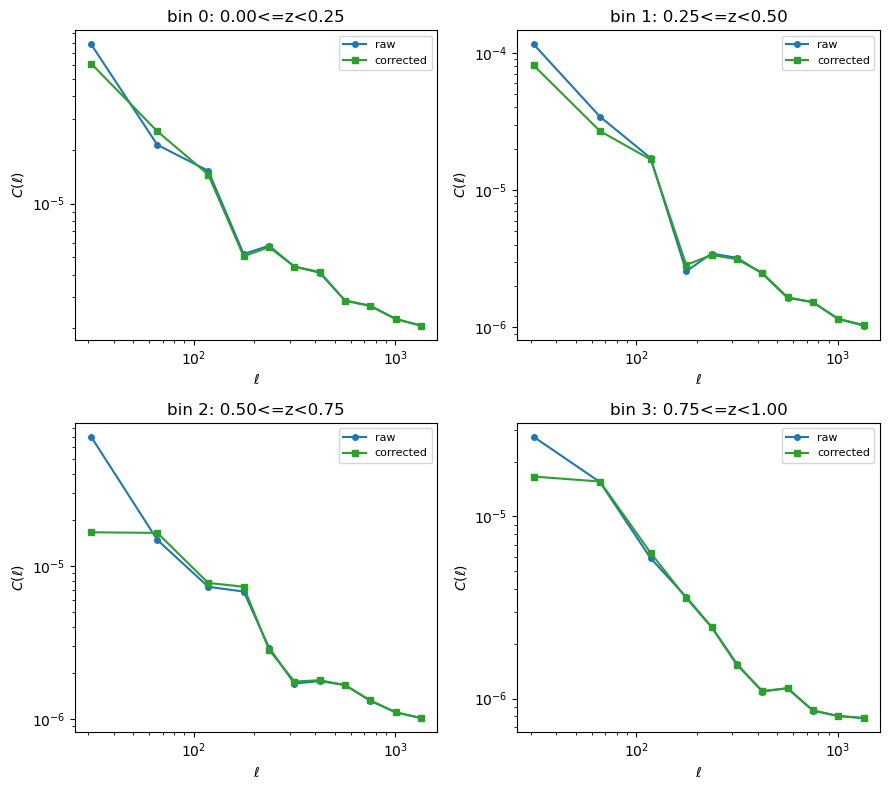

In [36]:
fig, axes = plt.subplots(2, 2, figsize=(9, 8))
axes = axes.flatten()
for b, ax in enumerate(axes):
    ax.plot(ell_nmt, cl_raw_zbins[b], 'o-', ms=4, color='tab:blue', label='raw')
    ax.plot(ell_nmt, cl_deproj_zbins[b], 's-', ms=4, color='tab:green', label='corrected')
    ax.set_xscale('log')
    ax.set_yscale('log')
    ax.set_title('bin {}: {:.2f}<=z<{:.2f}'.format(b, Z_EDGES[b], Z_EDGES[b + 1]))
    ax.set_xlabel(r'$\ell$')
    ax.set_ylabel(r'$C(\ell)$')
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()


### 5.3. Redshift evolution of the corrected C(ell)

The deprojected C(ell) from all four tomographic bins, together, to compare amplitude and shape across redshift directly.


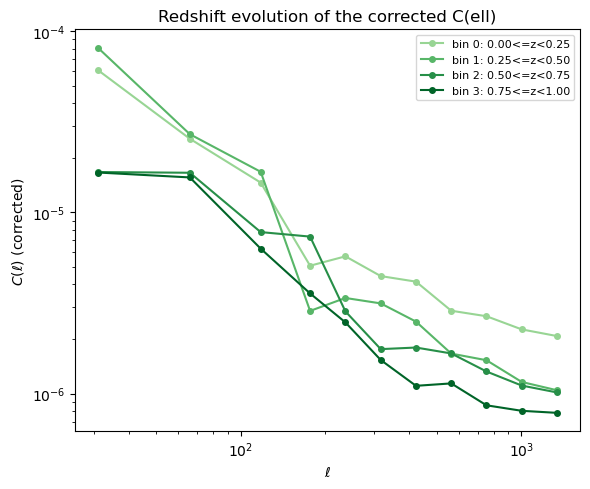

In [37]:
greens_cl = plt.cm.Greens(np.linspace(0.4, 0.9, N_ZBINS))
fig, ax = plt.subplots(figsize=(6, 5))
for b in range(N_ZBINS):
    ax.plot(ell_nmt, cl_deproj_zbins[b], 'o-', ms=4, color=greens_cl[b],
           label='bin {}: {:.2f}<=z<{:.2f}'.format(b, Z_EDGES[b], Z_EDGES[b + 1]))
ax.set_xscale('log')
ax.set_yscale('log')
ax.set_xlabel(r'$\ell$')
ax.set_ylabel(r'$C(\ell)$ (corrected)')
ax.set_title('Redshift evolution of the corrected C(ell)')
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()


<div class="alert alert-block alert-warning">
<b>Questions: the angular power spectrum C(ℓ)</b>

5a. `ELL_MIN` is set from the patch radius (Section 5). What would happen if you tried to measure a bandpower at ℓ=2 with a ~12°-diameter patch?<br>
5b. Compare, for the same tomographic bin, how much the systematics correction changes the amplitude of C(ℓ) (Section 5.2) versus w(θ) (Section 4.4). Do the real-space and harmonic-space views agree on how much systematics matter?<br>
5c. Look at the overall shape of C(ℓ): how does it vary with ℓ, and does that make sense given w(θ)'s shape (recall C(ℓ) and w(θ) are related by a transform — small θ corresponds to large ℓ and vice versa)? What does that imply for how a halo's internal structure (small scales / high ℓ) versus the large-scale clustering between halos (large scales / low ℓ) each show up in C(ℓ)?<br>
</div>


## 6. Going deeper

Three more exercises that build on the machinery above: a standard way to summarize w(θ)'s
shape (Exercise V), and a cosmology-free look at galaxy bias measured two independent ways —
in real space and in harmonic space (Exercises VI and VII).


<div class="alert alert-block alert-info">
<b>Exercise V: a power-law fit to w(θ)</b>

Classic galaxy-survey papers often summarize an angular correlation function with a single
power law, $w(\theta) = A_\omega\,\theta^{1-\gamma}$, fit by least squares in log-log space
(Connolly et al. 2002, ApJ 579, 42, [astro-ph/0107417](https://arxiv.org/abs/astro-ph/0107417),
§3.3; Wang, Brunner & Dolence 2013, MNRAS 432, 1961,
[arXiv:1303.2432](https://arxiv.org/abs/1303.2432), §5.4 and Table 3). Both papers measure the
SDSS *imaging* (not spectroscopic) catalog sliced by apparent magnitude rather than
tomographic photo-z bins, and find the amplitude decreasing toward fainter (higher-median-
redshift) slices — the magnitude-sliced analog of what you'd expect across our tomographic
bins.

Fit $A_\omega$ and $\gamma$ to the corrected w(θ) (`weighted_results[b]`) in each tomographic
bin — `scipy.optimize.curve_fit` on `log10(xi)` vs. `log10(theta)` is enough for a first pass
(a proper fit would use the full covariance matrix, as both papers do, rather than just the
diagonal errors).

*Guiding questions:*<br>
Va. How does the fitted amplitude $A_\omega$ change across the four tomographic bins? Is the trend consistent with what Section 4.5's plot already shows by eye?<br>
Vb. How does the fitted slope $\gamma$ compare across bins, and to the classic value $\gamma \approx 1.7$–$1.8$ found by Connolly (2002) and Wang (2013)?<br>
Vc. Over what range of θ is the power law actually a good fit? (Look at residuals; both papers find departures from a single power law at the smallest and largest scales they probe.)<br>
</div>


In [38]:
# TODO: for each zbin, fit log10(xi) = log10(A_omega) + (1-gamma)*log10(theta) to
# weighted_results[b] with scipy.optimize.curve_fit (or np.polyfit), restricting to theta
# bins where xi > 0. Overlay the fits on a copy of the Section 4.5 plot, and tabulate
# A_omega and gamma per bin.


<div class="alert alert-block alert-info">
<b>Exercise VI: relative bias, in real space</b>

On large scales, a galaxy sample's clustering amplitude tracks the underlying matter
clustering, scaled by the galaxy bias: $w_{\rm gal}(\theta) \approx b^2\, w_{\rm
matter}(\theta)$. Measuring $b$ itself needs a model for $w_{\rm matter}(\theta)$ — a
cosmological matter power spectrum, which is next class's topic. But the *ratio* of bias
between two samples drawn from the same redshift range doesn't need $w_{\rm matter}(\theta)$
at all: if both samples trace the same volume, the matter term is identical for both and
cancels in the ratio,

$$b_{\rm rel} = \frac{b_1}{b_2} = \sqrt{\frac{w_1(\theta)}{w_2(\theta)}}.$$

We test this by splitting one tomographic bin into a bright and a faint half by `i_mag` (same
`zbin` ⇒ same redshift range ⇒ the matter correlation function is the same for both),
measuring w(θ) for each with the exact same mask, randoms, and TreeCorr machinery as
Section 4.2, and taking the ratio. If linear bias holds, $b_{\rm rel}(\theta)$ should come out
close to flat; departures at small θ are a sign that nonlinear or halo-exclusion effects are
kicking in. (Exercise VII repeats this in harmonic space, using the `bright_mask`/`faint_mask`
split built here.)

*Guiding questions:*<br>
VIa. Is $b_{\rm rel}(\theta)$ roughly flat, or does it trend with scale? If it trends at small θ, which direction would you expect from halo exclusion (two galaxies cannot sit inside the same halo closer than its virial radius)?<br>
VIb. Which half — bright or faint — comes out more strongly biased? Does that match your intuition about which galaxies tend to live in more massive dark matter haloes?<br>
VIc. We split by observed `i_mag`, not by luminosity or stellar mass. Could dust extinction (`ebv`) or the width of the redshift bin itself fake part of this signal, rather than real bias?<br>
VId. This gives you $b_1/b_2$, not $b_1$ or $b_2$ individually. What additional ingredient — not available yet in this course — would let you turn this ratio into an absolute bias?<br>
</div>


In [39]:
# TODO: pick a tomographic bin (avoid the lowest, which likely has the fewest
# galaxies), split it into a bright and a faint half by i_mag (e.g. at the median) --
# name the two boolean masks `bright_mask`/`faint_mask` so Exercise VII can reuse them --
# and measure w(theta) for each half with compute_wtheta (Section 4.2), using the
# per-galaxy weight. Take the ratio sqrt(w_bright/w_faint) vs. theta and see whether
# it comes out roughly flat.


<div class="alert alert-block alert-info">
<b>Exercise VII: relative bias, in harmonic space</b>

Exercise VI measured $b_{\rm rel}(\theta) = \sqrt{w_1(\theta)/w_2(\theta)}$ in real space. The
same logic works directly in harmonic space: since both halves share the same redshift range,
their matter power spectrum is identical and cancels in the ratio
$b_{\rm rel}(\ell) = \sqrt{C_\ell^{\rm bright}/C_\ell^{\rm faint}}$, built with NaMaster
exactly as in Section 5.1.

Build (deprojected) overdensity fields for the same `bright_mask`/`faint_mask` split from
Exercise VI, auto-correlate each with NaMaster, and compare the resulting $b_{\rm rel}(\ell)$
to the real-space $b_{\rm rel}(\theta)$ from Exercise VI.

*Guiding questions:*<br>
VIIa. Do the real-space and harmonic-space measurements agree on the scale-averaged relative bias? This kind of cross-check — the same physics measured two independent ways — is exactly what real surveys use to build confidence in a result (e.g. DES Y1's harmonic-vs-real-space comparison, [arXiv:2103.14190](https://arxiv.org/abs/2103.14190)).<br>
VIIb. Small θ in real space roughly corresponds to large ℓ in harmonic space. Does the scale where $b_{\rm rel}$ starts departing from flat line up between the two plots?<br>
VIIc. Which measurement would you trust more at the largest scales probed — real-space w(θ) or harmonic-space C(ℓ)? (Think about what each representation does with the survey mask.)<br>
</div>


In [40]:
# TODO: using the same bright/faint split from Exercise VI, build a (deprojected)
# overdensity field for each half as in Section 5.1, auto-correlate each with
# NaMaster (nmt.compute_coupled_cell + workspace.decouple_cell), and take the ratio
# sqrt(C_ell_bright / C_ell_faint). Compare to the real-space result from Exercise VI.
